# Keep社区：评论文本分析

## tl;dr
在11,595条去重评论中，清理后字符数中位数为6；11.8%仅有标记或符号。其他用户发言的鼓励或赞许词命中率为16.9%，帖主发言的感谢词命中率为7.9%。这些结果描述字面表达，不估计情感、社会支持或因果效果。

## Context & Methods
对应RQ3：评论主要表达什么、用户如何连接、互动集中在哪里？本Notebook负责评论内容，关系结构见主分析及扩展实验Notebook。

### Key Assumptions
- 来源：2026Data/Keep Data/sample_comment_2022.csv；通过sample_post_2022.csv识别所属帖主。
- 按cmtId去重；不同ID下的重复短句和84次自我互动保留。
- 统一全半角，移除URL和方括号标记，词项每条评论至多计一次。
- 规则见code/comment_text_config.json；四类特征可重叠，未进行独立人工语义验证。
- 角色按每条评论界定；同一用户可在不同帖子中切换角色，用户覆盖不能相加。

### 1. 环境与配置

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "code/analyze_comment_text.py").exists():
    ROOT = ROOT / "projects/group"
sys.path.insert(0, str(ROOT / "code"))
import analyze_comment_text as comments
display(pd.DataFrame([{ "特征": rule["label"], "规则": "、".join(rule["terms"]) } for rule in comments.CFG["features"].values()]))

,特征,规则
0,鼓励或赞许词,加油、棒棒、真棒、太棒、很棒、厉害、优秀、佩服、精彩、漂亮、好看、点赞、好赞
1,感谢词,谢谢、感谢、多谢、谢啦、谢了、感恩
2,问候词,早安、晚安、早上好、晚上好、下午好、中午好、周末好、节日快乐、新年快乐、生日快乐
3,问号,?、？


## Data
### 2. 重新读取输入并计算汇总
只输出汇总表和图形；原始评论、ID及逐条特征均不写入公开结果。

In [2]:
summary = comments.analyze()
keys = ["raw_comments", "comments", "duplicate_ids_removed", "missing_content", "senders", "posts", "markers_or_symbols_only", "median_clean_length", "repeated_normalized_text_comments"]
display(pd.DataFrame({"指标": keys, "数值": [summary[key] for key in keys]}))
print("来源及规则SHA-256保存在results/comment_text_summary.json。")

,指标,数值
0,raw_comments,13511.0
1,comments,11595.0
2,duplicate_ids_removed,1916.0
3,missing_content,0.0
4,senders,2910.0
5,posts,1323.0
6,markers_or_symbols_only,1373.0
7,median_clean_length,6.0
8,repeated_normalized_text_comments,3362.0


来源及规则SHA-256保存在results/comment_text_summary.json。


## Results
### 3. 常见词与发言用户覆盖
每条评论内词项去重后计数；至少覆盖5位发言者。频数不能直接替代参与广度。

,term,comments,share,senders,sender_share
0,加油,612,0.0528,431,0.1481
1,哈哈哈,544,0.0469,68,0.0234
2,谢谢,359,0.0310,53,0.0182
3,哈哈哈哈,323,0.0279,34,0.0117
4,厉害,258,0.0223,219,0.0753
5,早安,171,0.0147,43,0.0148
6,喜欢,164,0.0141,68,0.0234
7,好看,149,0.0129,92,0.0316
8,愉快,111,0.0096,32,0.0110
9,早上好,110,0.0095,37,0.0127


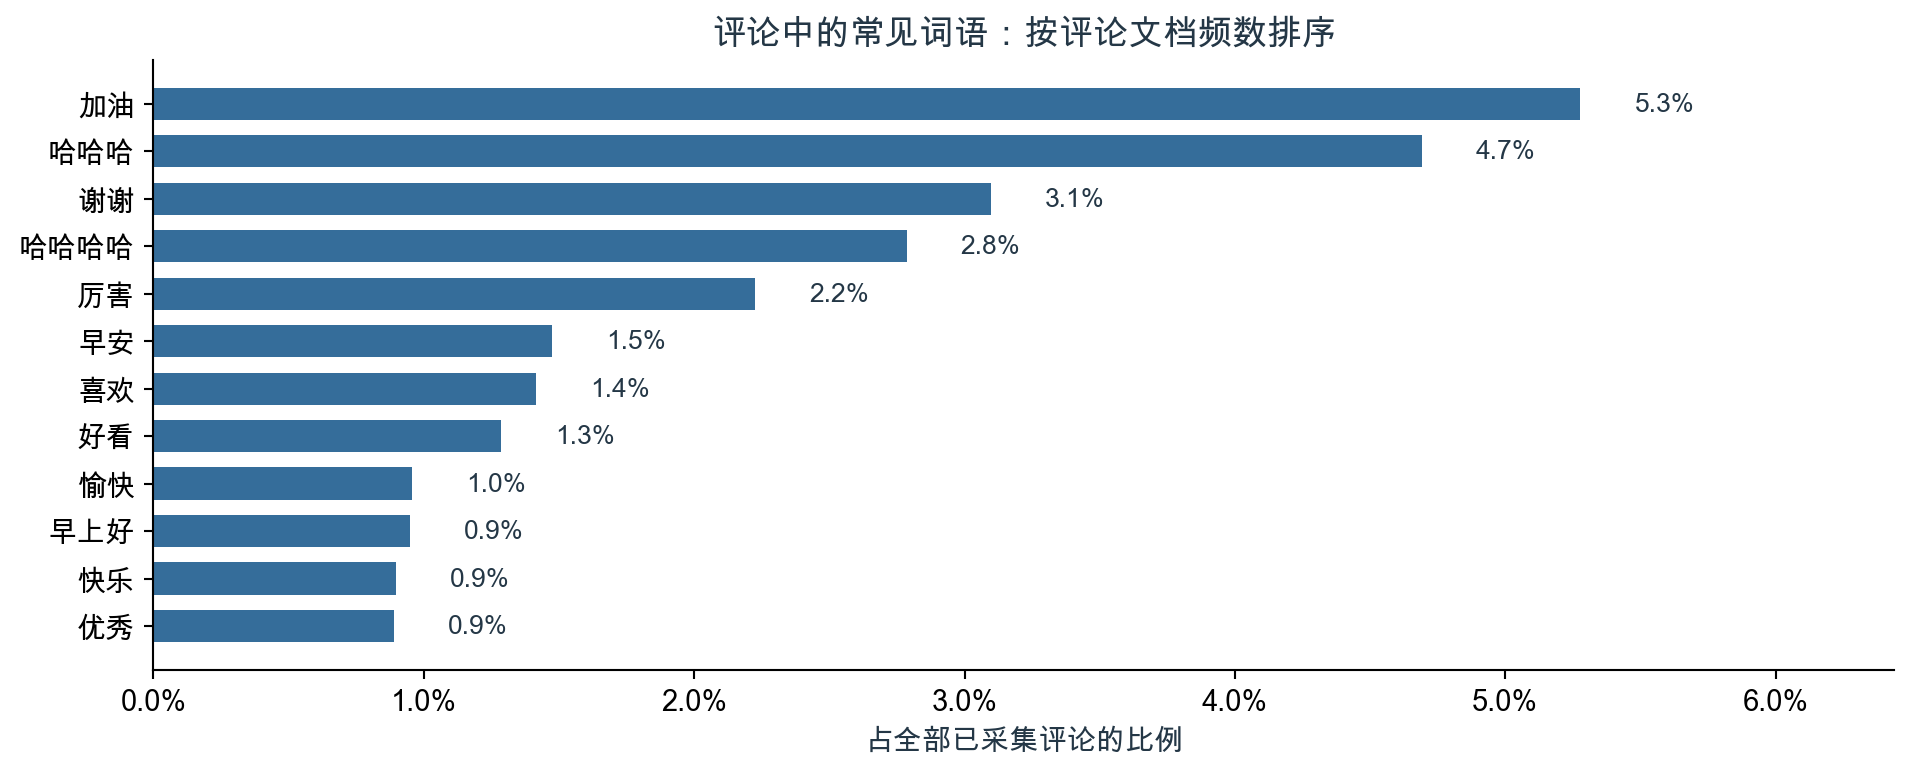

In [3]:
terms = pd.read_csv(ROOT / "results/comment_text_terms.csv")
display(terms.head(12).round(4))
display(Image(filename=str(ROOT / "figures/14_comment_words.png"), width=950))

“加油”出现在612条评论、覆盖431位用户；“谢谢”出现在359条评论、覆盖53位用户。不同短句的次数与覆盖人数并不成比例。

### 4. 字面表达与角色
分母为该角色的全部已采集评论。规则可重叠，问号不代表真实提问；角色差异不是干预效果。

,role,label,n,hits,share,senders_hit
0,全部评论,鼓励或赞许词,11595,1413,0.1219,876
1,全部评论,感谢词,11595,389,0.0335,68
2,全部评论,问候词,11595,551,0.0475,136
3,全部评论,问号,11595,427,0.0368,200
4,其他用户发言,鼓励或赞许词,7192,1214,0.1688,849
5,其他用户发言,感谢词,7192,42,0.0058,38
6,其他用户发言,问候词,7192,314,0.0437,121
7,其他用户发言,问号,7192,298,0.0414,184
8,帖主发言,鼓励或赞许词,4403,199,0.0452,27
9,帖主发言,感谢词,4403,347,0.0788,30


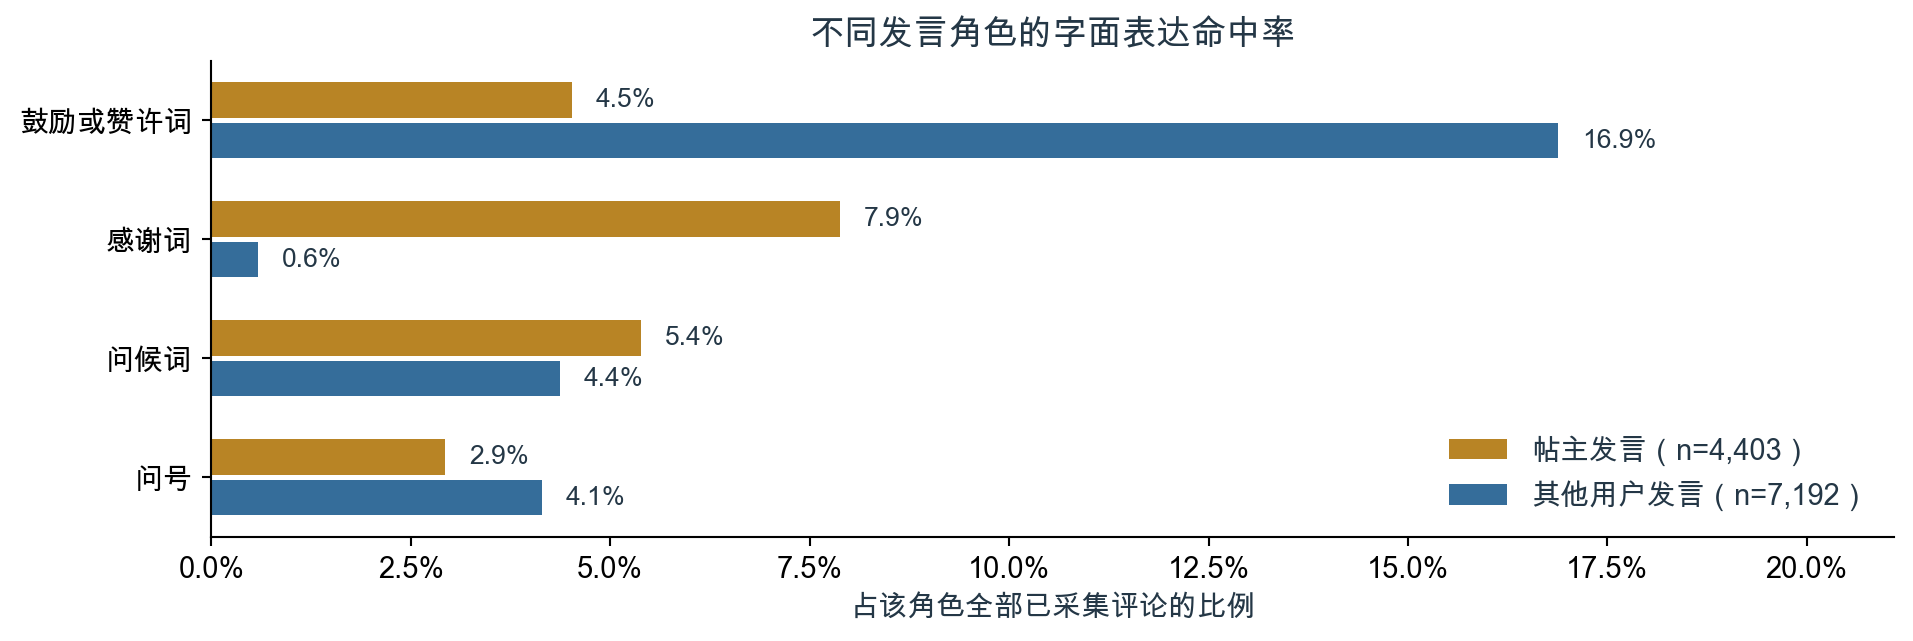

In [4]:
features = pd.read_csv(ROOT / "results/comment_text_features.csv")
display(features[["role", "label", "n", "hits", "share", "senders_hit"]].round(4))
display(Image(filename=str(ROOT / "figures/15_comment_expressions.png"), width=950))

### 5. 独立复核
另从原始输入用向量化清理、逐词包含规则及词项展开聚合重算，不调用分析函数的统计助手。

In [5]:
import validate_comment_text
checks = validate_comment_text.main()
assert all(row["passed"] for row in checks)
display(pd.DataFrame(checks))

Passed 19 independent comment-text checks.


,check,passed
0,唯一评论、去重规模及关联,True
1,缺失、用户与帖子分母,True
2,仅标记或符号计数,True
3,清理后字符数中位数,True
4,全部评论：鼓励或赞许词,True
5,全部评论：感谢词,True
6,全部评论：问候词,True
7,全部评论：问号,True
8,其他用户发言：鼓励或赞许词,True
9,其他用户发言：感谢词,True


## Takeaways
评论中的短句与字面表达可以帮助描述已采集交流。其他用户与帖主的表达分布不同，但未验证逐线程的“鼓励—感谢”链条。评论内容与网络是RQ3的两个侧面；不能据此解释点赞回归的系数或识别健康、留存效果。